# 看得见的 PTv3：Utonia-tiny 逐步实验

每一步先说明**看哪幅图、看什么变化**，再给出代码。点击代码格，按 `Shift + Enter` 运行。

本教程用三块已知形状的模拟表面解释接口。预训练模型只提取特征。后面的三分类头会在这批模拟点上做小型训练，训练拟合结果与真实建筑效果分别理解。

最后会预览你的真实 PCD，但默认不对它运行模型。

**阅读方式：**先直接看每节已保存的图。想亲手实验时，从第 1 节开始按顺序运行。第 7 节的滑块需要先运行第 1～7 节代码，连接着 Python 内核才会更新。

## 1. 环境、源码和整个流程

先确认当前 Python 来自 `pure3d-ptv3`。下图会一直沿用同一套颜色：绿色是模拟地面，蓝色是模拟墙面，橙色是模拟斜坡。

In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
import ipywidgets as widgets
import point_transformer_v3 as ptv3

font = Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 100, 'font.size': 11})
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Python:', sys.executable)
print('源码:', ptv3.__file__)
print('PyTorch:', torch.__version__, '| 使用设备:', device)


Python: /home/cjh/miniconda3/envs/pure3d-ptv3/bin/python
源码: /home/cjh/Pure3D_ws/utils/PointTransformerV3/src/point_transformer_v3/__init__.py
PyTorch: 2.10.0+cu128 | 使用设备: cuda


下面是绘图工具，已经折叠。这个代码格也要运行，但可以暂时不阅读内部实现。它们只负责画图，不修改模型和点云。

In [2]:
CLASS_NAMES = ['模拟地面', '模拟墙面', '模拟斜坡']
CLASS_COLORS = ['#20965e', '#3678c4', '#e38c2b']
CLASS_CMAP = ListedColormap(CLASS_COLORS)

def finish(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def scene(ax, xyz, values=None, title='', selected=None, categorical=False):
    options = dict(s=17, alpha=0.9, depthshade=False)
    if values is None:
        ax.scatter(*xyz.T, color='#536a82', **options)
    elif categorical:
        ax.scatter(*xyz.T, c=values, cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, **options)
    else:
        ax.scatter(*xyz.T, c=values, **options)
    if selected is not None:
        p = xyz[selected]
        ax.scatter(*p, s=160, facecolors='none', edgecolors='#d31d48', linewidths=2, depthshade=False)
        ax.text(*p, f'  P{selected}', color='#b6153b', fontsize=10)
    ax.set(xlabel='X (m)', ylabel='Y (m)', zlabel='Z (m)', title=title)
    ax.view_init(elev=27, azim=-62)
    bounds = np.ptp(xyz, axis=0)
    ax.set_box_aspect(np.maximum(bounds, 0.3))

def labeled_legend(ax):
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], marker='o', linestyle='', color=c, label=n)
               for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
    ax.legend(handles=handles, loc='upper left', fontsize=9)

def pca_rgb(array):
    centered = array - array.mean(axis=0)
    _, _, axes = np.linalg.svd(centered, full_matrices=False)
    axes = axes[:3].T
    for k in range(3):
        if axes[np.abs(axes[:, k]).argmax(), k] < 0:
            axes[:, k] *= -1
    projected = centered @ axes
    lo, hi = np.percentile(projected, [2, 98], axis=0)
    return np.clip((projected - lo) / np.maximum(hi - lo, 1e-8), 0, 1)

def comparison(xyz, truth, before, after):
    fig = plt.figure(figsize=(13, 4.2))
    entries = [(truth, '已知标签（生成数据时给定）'),
               (before, '随机任务头：训练前'),
               (after, '训练后：同一批模拟训练点')]
    for i, (labels, title) in enumerate(entries):
        ax = fig.add_subplot(1, 3, i + 1, projection='3d')
        scene(ax, xyz, labels, title, categorical=True)
        if i > 0:
            wrong = labels != truth
            if wrong.any():
                ax.scatter(*xyz[wrong].T, s=44, facecolors='none', edgecolors='#d31d48', linewidths=0.7, depthshade=False)
        if i == 0: labeled_legend(ax)
    finish(fig)


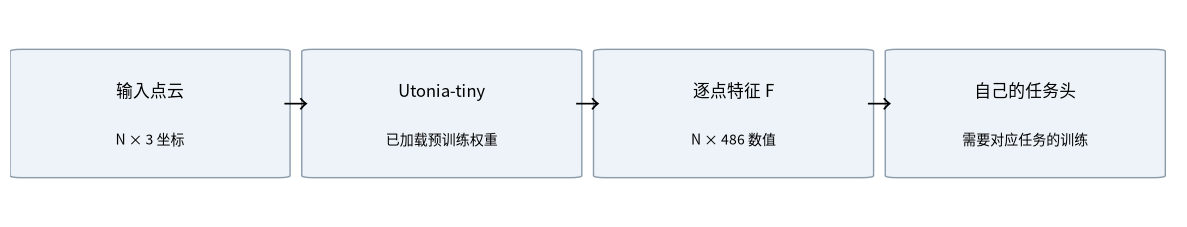

In [3]:
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.axis('off')
stages = [('输入点云', 'N × 3 坐标'), ('Utonia-tiny', '已加载预训练权重'),
          ('逐点特征 F', 'N × 486 数值'), ('自己的任务头', '需要对应任务的训练')]
for i, (name, detail) in enumerate(stages):
    x = 0.01 + i * 0.25
    ax.add_patch(FancyBboxPatch((x, 0.2), 0.22, 0.6, boxstyle='round,pad=0.01',
                               facecolor='#edf3f8', edgecolor='#8b9baa', transform=ax.transAxes))
    ax.text(x + 0.11, 0.58, name, ha='center', transform=ax.transAxes, fontsize=12)
    ax.text(x + 0.11, 0.35, detail, ha='center', transform=ax.transAxes, fontsize=10)
    if i < 3: ax.text(x + 0.235, 0.5, '→', transform=ax.transAxes, ha='center', fontsize=18)
finish(fig)


## 2. 权重加载了什么？

权重是模型中已经学到的参数。下面会显示实际 `.pth` 路径，并画出第一组二维权重矩阵的一小部分。**矩阵中的颜色是参数数值，不是地面或障碍类别。**

权重路径: /home/cjh/.cache/huggingface/hub/models--Pointcept--Utonia/snapshots/9457f025e36c7001ee962a542f0d27a5b600e1e7/utonia_tiny.pth
模型参数量: 9,326,088


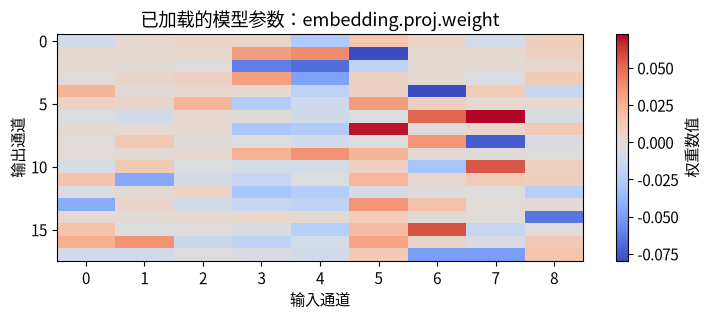

In [4]:
model = ptv3.load('utonia_tiny', device=device, warmup=False)
info = model.weights_info['backbone']
print('权重路径:', info.get('path', info.get('file')))
print('模型参数量:', f'{sum(p.numel() for p in model.parameters()):,}')
name, parameter = next((n, p) for n, p in model.named_parameters() if p.ndim == 2)
matrix = parameter.detach().float().cpu().numpy()[:32, :32]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
image = ax.imshow(matrix, aspect='auto', cmap='coolwarm')
ax.set(title=f'已加载的模型参数：{name}', xlabel='输入通道', ylabel='输出通道')
fig.colorbar(image, ax=ax, label='权重数值')
finish(fig)


源码通过 `import point_transformer_v3 as ptv3` 使用。它已经以可编辑模式安装，修改工作区中的源码会影响这个环境。

权重不必放进源码目录。手动指定兼容权重时使用：
```python
model = ptv3.load('utonia_tiny', weights='/你的路径/utonia_tiny.pth', device=device, warmup=False)
```
自动加载时使用 Hugging Face 缓存。

## 3. 用三块表面看清输入

左图全部使用相同颜色，表示模型拿到的几何点。右图的类别颜色由我们在生成数据时指定，作为后面训练任务头的玩具标签。**右图并不是 Utonia 预测出来的。**

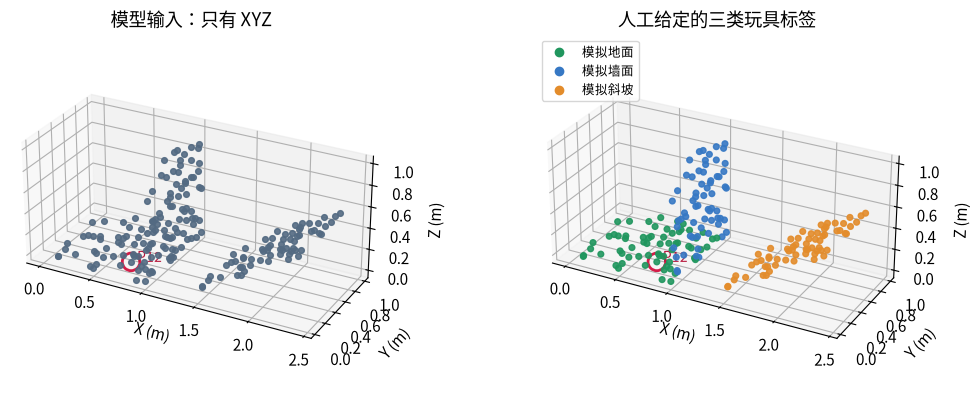

coord / color / normal 的形状: (192, 3) (192, 3) (192, 3)


In [5]:
rng = np.random.default_rng(7)
n = 64  # 每块表面 64 个点，共 192 个
uv = rng.random((n, 2), dtype=np.float32)
floor = np.column_stack((uv[:, 0], uv[:, 1], np.zeros(n)))
wall = np.column_stack((np.ones(n), uv[:, 0], uv[:, 1]))
ramp = np.column_stack((1.4 + uv[:, 0], uv[:, 1], 0.6 * uv[:, 0]))
coord = np.concatenate((floor, wall, ramp)).astype(np.float32)
toy_labels_np = np.repeat(np.arange(3), n)
color = np.zeros_like(coord)  # 缺少 RGB 时使用零数组
normal = np.zeros_like(coord) # 缺少法向时使用零数组
SELECTED_POINT = 12

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(121, projection='3d')
scene(ax, coord, title='模型输入：只有 XYZ', selected=SELECTED_POINT)
ax = fig.add_subplot(122, projection='3d')
scene(ax, coord, toy_labels_np, '人工给定的三类玩具标签', selected=SELECTED_POINT, categorical=True)
labeled_legend(ax)
finish(fig)
print('coord / color / normal 的形状:', coord.shape, color.shape, normal.shape)


## 4. 点云如何变成数组？

每一行代表同一个点，三列是 X、Y、Z。红框强调的点 `P12` 会在后面的特征图里继续出现。实际输入的 XYZ、颜色、法向是三个独立数组。

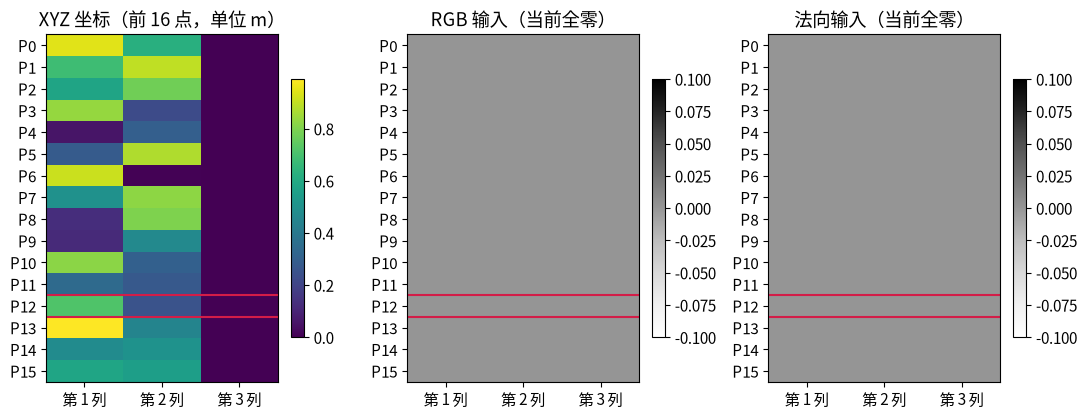

In [6]:
shown = np.arange(16)
fig, axes = plt.subplots(1, 3, figsize=(11, 4.3))
for ax, array, title, cmap in zip(axes, [coord, color, normal],
        ['XYZ 坐标（前 16 点，单位 m）', 'RGB 输入（当前全零）', '法向输入（当前全零）'],
        ['viridis', 'Greys', 'Greys']):
    image = ax.imshow(array[shown], aspect='auto', cmap=cmap)
    ax.set(title=title, xticks=[0, 1, 2], xticklabels=['第 1 列', '第 2 列', '第 3 列'])
    ax.set_yticks(shown, [f'P{i}' for i in shown])
    ax.axhline(SELECTED_POINT - 0.5, color='#d31d48', linewidth=1.5)
    ax.axhline(SELECTED_POINT + 0.5, color='#d31d48', linewidth=1.5)
    fig.colorbar(image, ax=ax, fraction=0.05)
finish(fig)


## 5. 一次前向：N×3 → N×486

`embed()` 在内部完成准备点云、模型前向和逐点映射。下面左图仍是输入 XYZ，右图显示输出特征的前 32 个点、前 48 个通道。完整输出每点有 486 个通道。

每个特征通道的意义由预训练决定，不能把某一列直接叫作“地面”或“cost”。

输入: (192, 3) → 输出: (192, 486)


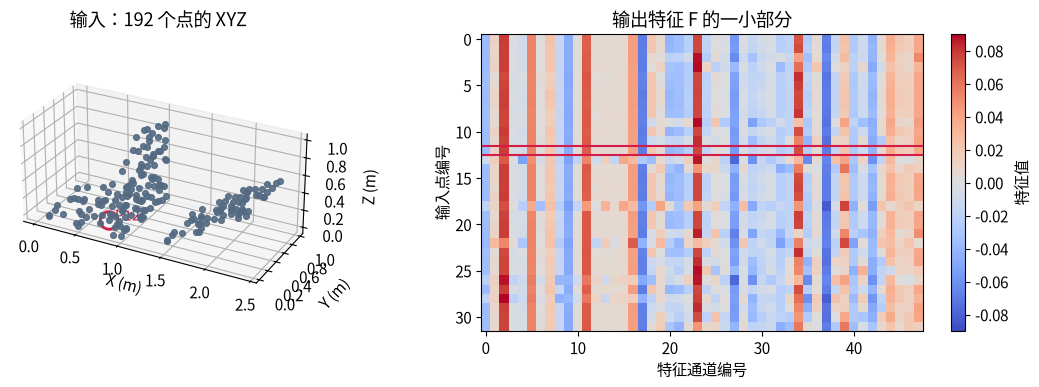

In [7]:
features = model.embed(coord, color, normal)
feature_array = features.float().cpu().numpy()
print('输入:', coord.shape, '→ 输出:', tuple(features.shape))

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121, projection='3d')
scene(ax, coord, title='输入：192 个点的 XYZ', selected=SELECTED_POINT)
ax = fig.add_subplot(122)
limit = max(float(np.abs(feature_array[:32, :48]).max()), 1e-6)
image = ax.imshow(feature_array[:32, :48], aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.axhline(SELECTED_POINT - 0.5, color='#d31d48', linewidth=1.5)
ax.axhline(SELECTED_POINT + 0.5, color='#d31d48', linewidth=1.5)
ax.set(title='输出特征 F 的一小部分', xlabel='特征通道编号', ylabel='输入点编号')
fig.colorbar(image, ax=ax, label='特征值')
finish(fig)


## 6. 把特征放回点云上看

左图是我们给定的类别。右图把 486 维特征用 PCA 压缩成三维，再映射成 RGB 颜色。相似颜色表示压缩后的特征接近，**PCA 颜色没有固定类别含义**，也不是模型恢复出的真实 RGB。

两幅图使用完全相同的 XYZ。模型提取特征后，点的位置没有改变。

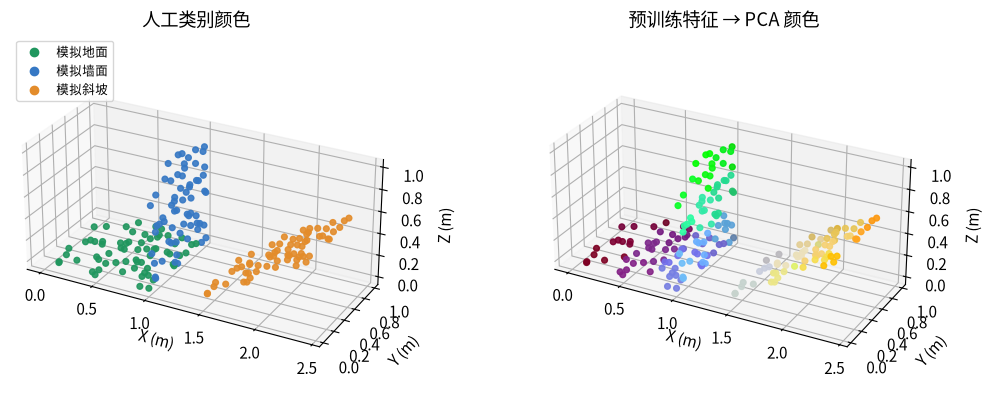

In [8]:
feature_rgb = pca_rgb(feature_array)
fig = plt.figure(figsize=(11, 4.3))
ax = fig.add_subplot(121, projection='3d')
scene(ax, coord, toy_labels_np, '人工类别颜色', categorical=True)
labeled_legend(ax)
ax = fig.add_subplot(122, projection='3d')
scene(ax, coord, feature_rgb, '预训练特征 → PCA 颜色')
finish(fig)


## 7. 选一个点，看它的 486 维特征和“像谁”

红圈是选中的点。中间显示它的特征向量，右图显示所有点与它的余弦相似度。先看默认的 `P12`，再拖动控件换成墙面点（64～127）或斜坡点（128～191）。

特征相似度是可观察的模型输出，不保证相似的点就属于同一语义类别。

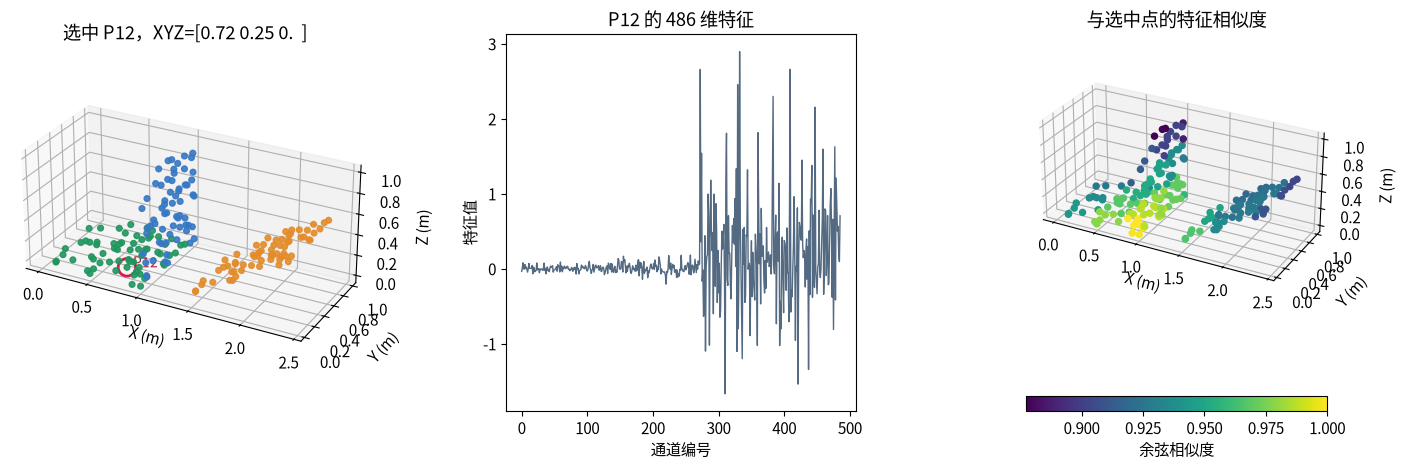

IntSlider(value=12, continuous_update=False, description='点编号', max=191)

Output()

In [9]:
def inspect_point(point_id):
    norms = np.maximum(np.linalg.norm(feature_array, axis=1, keepdims=True), 1e-8)
    unit = feature_array / norms
    similarity = np.clip(unit @ unit[point_id], -1, 1)
    fig = plt.figure(figsize=(14, 4.8))
    ax = fig.add_subplot(131, projection='3d')
    scene(ax, coord, toy_labels_np, f'选中 P{point_id}，XYZ={np.round(coord[point_id], 2)}', selected=point_id, categorical=True)
    ax = fig.add_subplot(132)
    ax.plot(feature_array[point_id], linewidth=1, color='#536a82')
    ax.set(title=f'P{point_id} 的 486 维特征', xlabel='通道编号', ylabel='特征值')
    ax = fig.add_subplot(133, projection='3d')
    dots = ax.scatter(*coord.T, c=similarity, cmap='viridis', s=19, depthshade=False)
    ax.set(title='与选中点的特征相似度', xlabel='X (m)', ylabel='Y (m)', zlabel='Z (m)')
    ax.view_init(elev=27, azim=-62)
    ax.set_box_aspect(np.maximum(np.ptp(coord, axis=0), 0.3))
    fig.colorbar(dots, ax=ax, label='余弦相似度', orientation='horizontal', fraction=0.04, pad=0.18)
    fig.tight_layout(w_pad=4.0)
    plt.show()
    plt.close(fig)

inspect_point(SELECTED_POINT)  # 即使控件尚未运行，也先显示一幅结果
point_slider = widgets.IntSlider(value=SELECTED_POINT, min=0, max=len(coord)-1,
                                 description='点编号', continuous_update=False)
point_output = widgets.Output()
def update_point(change):
    with point_output:
        point_output.clear_output(wait=True)
        inspect_point(change['new'])
point_slider.observe(update_point, names='value')
display(point_slider, point_output)


## 8. 为什么随机任务头不能识别语义？

我们在特征后面接一个 `Linear(486, 3)`，输出三个类别的分数。这里先画出随机任务头的分类。**背景中的 Utonia 已预训练，但这个新任务头还没有学过我们的标签。**

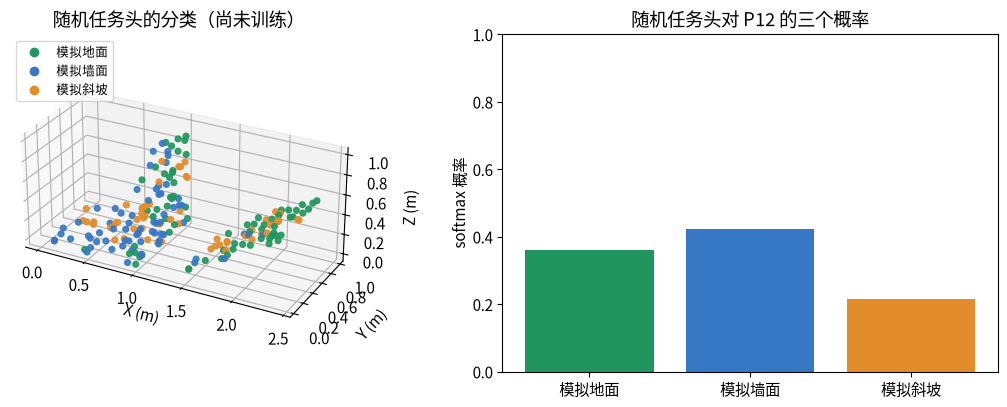

特征 → 任务头分数: (192, 486) → (192, 3)


In [10]:
torch.manual_seed(7)
demo_features = features.clone().detach()
# 用当前模拟训练点的统计量标准化，帮助这个小型任务头训练。
feature_mean = demo_features.mean(0, keepdim=True)
feature_std = demo_features.std(0, keepdim=True).clamp_min(1e-4)
head_inputs = (demo_features - feature_mean) / feature_std
demo_head = torch.nn.Linear(features.shape[1], 3).to(features.device)
with torch.no_grad():
    scores_before = demo_head(head_inputs)
    probabilities_before = scores_before.softmax(dim=1).cpu().numpy()
    predicted_before = scores_before.argmax(dim=1).cpu().numpy()

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(121, projection='3d')
scene(ax, coord, predicted_before, '随机任务头的分类（尚未训练）', categorical=True)
labeled_legend(ax)
ax = fig.add_subplot(122)
ax.bar(CLASS_NAMES, probabilities_before[SELECTED_POINT], color=CLASS_COLORS)
ax.set(ylim=(0, 1), title=f'随机任务头对 P{SELECTED_POINT} 的三个概率', ylabel='softmax 概率')
finish(fig)
print('特征 → 任务头分数:', tuple(features.shape), '→', tuple(scores_before.shape))


## 9. 训练后发生了什么？

接下来只训练线性任务头 200 步，Utonia 特征保持不变。训练标签来自模拟表面的生成过程。

曲线显示 loss 和训练准确率。底下三幅点云使用相同的视角，红色空心圈标出分类错误。**训练前后都评估同一批模拟训练点，因此这里只展示拟合过程，不表示新场景效果。**

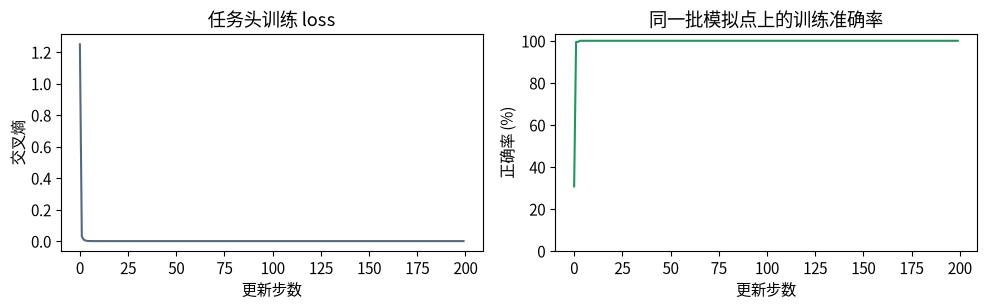

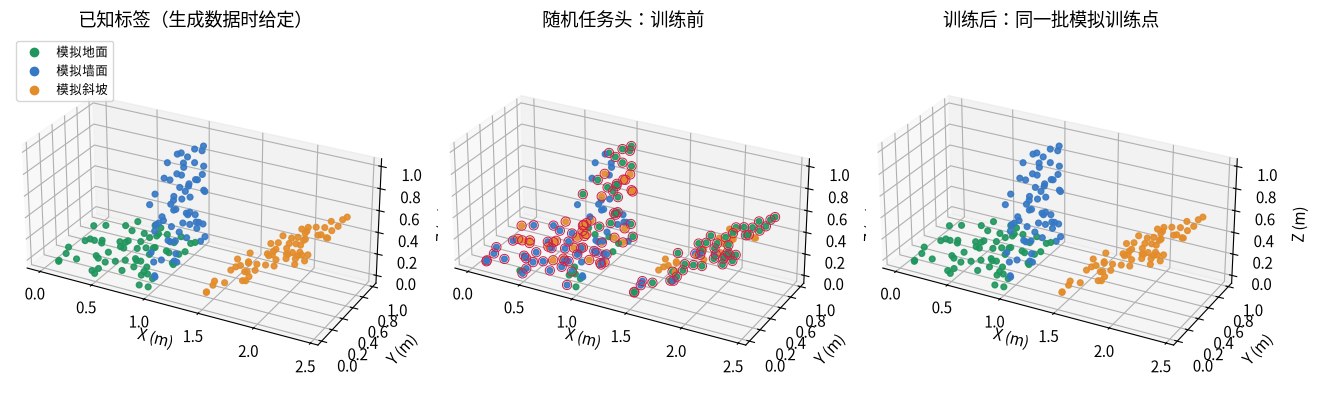

训练前: 30.7% | 训练后: 100.0%


In [11]:
toy_labels = torch.as_tensor(toy_labels_np, dtype=torch.long, device=features.device)
optimizer = torch.optim.AdamW(demo_head.parameters(), lr=0.02, weight_decay=0.001)
loss_history, accuracy_history = [], []
for step in range(200):
    optimizer.zero_grad()
    scores = demo_head(head_inputs)
    loss = torch.nn.functional.cross_entropy(scores, toy_labels)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    accuracy_history.append((scores.argmax(1) == toy_labels).float().mean().item())
with torch.no_grad():
    predicted_after = demo_head(head_inputs).argmax(1).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(loss_history, color='#536a82')
axes[0].set(title='任务头训练 loss', xlabel='更新步数', ylabel='交叉熵')
axes[1].plot(np.array(accuracy_history) * 100, color='#20965e')
axes[1].set(title='同一批模拟点上的训练准确率', xlabel='更新步数', ylabel='正确率 (%)', ylim=(0, 103))
finish(fig)
comparison(coord, toy_labels_np, predicted_before, predicted_after)
print('训练前:', f'{np.mean(predicted_before == toy_labels_np):.1%}', '| 训练后:', f'{np.mean(predicted_after == toy_labels_np):.1%}')


## 10. 用混淆矩阵核对结果

行是真实类别，列是任务头预测类别。理想情况下数字集中在对角线上。每类只有 64 个模拟训练点。

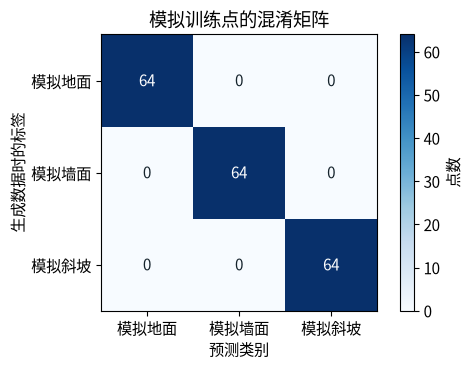

In [12]:
confusion = np.zeros((3, 3), dtype=int)
np.add.at(confusion, (toy_labels_np, predicted_after), 1)
fig, ax = plt.subplots(figsize=(5.4, 3.8))
image = ax.imshow(confusion, cmap='Blues', vmin=0, vmax=n)
for row in range(3):
    for col in range(3):
        ax.text(col, row, str(confusion[row, col]), ha='center', va='center',
                color='white' if confusion[row, col] > n/2 else '#15232c')
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
       xlabel='预测类别', ylabel='生成数据时的标签', title='模拟训练点的混淆矩阵')
fig.colorbar(image, ax=ax, label='点数')
finish(fig)


## 11. 预览你自己的 PCD：这里只看原始几何

下面从 `rot_stairs.pcd` 按文件索引选取 5,000 个点，画出三维与俯视图。**没有调用模型、没有分类、没有补全。** 颜色仅表示原始 Z 高度。抽样可能漏掉细栏杆，所以这不是结构质量评价。

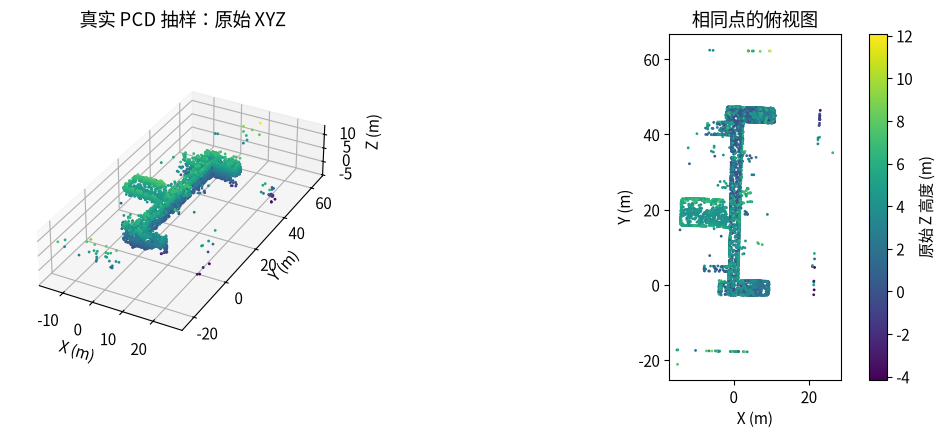

文件点数：5,886,268，这里只预览 5,000 点。


In [13]:
from importlib.util import spec_from_file_location, module_from_spec
source = Path('/home/cjh/Pure3D_ws/Reconstruction/test.py')
spec = spec_from_file_location('pure3d_example', source)
pcd_reader = module_from_spec(spec)
spec.loader.exec_module(pcd_reader)
pcd_path = Path('/home/cjh/Pure3D_ws/datasets/rot_stairs/raw.pcd')
preview_xyz, preview_normal, total_points = pcd_reader.read_binary_pcd_sample(pcd_path, 5000)

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(121, projection='3d')
dots = ax.scatter(*preview_xyz.T, c=preview_xyz[:, 2], cmap='viridis', s=1, depthshade=False)
ax.set(title='真实 PCD 抽样：原始 XYZ', xlabel='X (m)', ylabel='Y (m)', zlabel='Z (m)')
ax.set_box_aspect(np.maximum(np.ptp(preview_xyz, axis=0), 0.3))
ax.view_init(elev=32, azim=-62)
ax = fig.add_subplot(122)
dots = ax.scatter(preview_xyz[:, 0], preview_xyz[:, 1], c=preview_xyz[:, 2], cmap='viridis', s=1)
ax.set(title='相同点的俯视图', xlabel='X (m)', ylabel='Y (m)', aspect='equal')
fig.colorbar(dots, ax=ax, label='原始 Z 高度 (m)')
finish(fig)
print(f'文件点数：{total_points:,}，这里只预览 {len(preview_xyz):,} 点。')


## 12. 真实 PCD 的模型示例：由你主动开启

保留原来的开关。默认 `False`，因此“运行全部”不会对真实 PCD 提取特征。需要学习这一步时，将其改成 `True`。右图会出现 PCA 特征颜色，不是语义预测或 trav_cost。

In [14]:
RUN_PCD_EXAMPLE = False
if RUN_PCD_EXAMPLE:
    pcd_xyz, pcd_normal, total = pcd_reader.read_binary_pcd_sample(pcd_path, 512)
    pcd_features = model.embed(pcd_xyz, np.zeros_like(pcd_xyz), pcd_normal)
    pcd_rgb = pca_rgb(pcd_features.float().cpu().numpy())
    fig = plt.figure(figsize=(11, 4))
    scene(fig.add_subplot(121, projection='3d'), pcd_xyz, title='512 个真实抽样点：输入')
    scene(fig.add_subplot(122, projection='3d'), pcd_xyz, pcd_rgb, '相同点：PCA 特征颜色')
    finish(fig)
    print('PCD 特征形状:', tuple(pcd_features.shape))
else:
    display(Markdown('**真实 PCD 模型推理未开启。上面的模拟数据实验和原始几何预览已经完成。**'))


**真实 PCD 模型推理未开启。上面的模拟数据实验和原始几何预览已经完成。**

## 你现在应能区分的四件事

| 所见结果 | 它的含义 |
|---|---|
| 原始 XYZ 点云 | 传感器或模拟数据的坐标 |
| 特征热力图、PCA 颜色 | 预训练模型的空间表示 |
| 随机任务头颜色 | 未经任务训练的输出 |
| 玩具任务头训练后颜色 | 当前模拟训练点上的拟合结果 |

真正的行人过滤、楼梯/栏杆识别、地面补全和 trav_cost 仍需要相应任务数据与训练。现有 ScanNet-20 类别不含专门的 person、stair、railing。

`embed()` 是无梯度推理接口。训练自己的头时可以固定这些特征。要微调骨干，则使用 `prepare -> model(point)` 的可求梯度前向。大型建筑还需要带上下文的空间分块。